# CrusherBayes con retención en los diez muestreos: los intervalos predictivos frente a la banda de CrusherCal, lo que identifican los muestreos y el criterio de descarte aplicado tal como está escrito

**Pregunta:** ¿Predice CrusherBayes, la calibración bayesiana del motor con una discrepancia estructural, un muestreo retenido mejor que la recta de la abertura y da un intervalo más estrecho y calibrado que la banda de CrusherCal, y el criterio escrito antes de la corrida lo conserva o lo descarta?

- **Nivel:** 4, el método propuesto por el producto
- **Requisitos previos:** los notebooks 01 y 02 de este tema y el notebook 04 del tema 06
- **Tiempo de lectura:** unos 60 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir qué afirma CrusherBayes frente al punto único calibrado del artículo, y qué resultado lo descartaría, enunciado antes de la corrida;
- puntuar sus predicciones con retención y sus intervalos de 80 por ciento en los diez muestreos frente a la recta de la abertura, el modelo base, la regresión libre y la banda de CrusherCal;
- leer la tabla de contracción para decir qué parámetros identifican los diez muestreos y cuáles quedan en su a priori;
- leer la comparación pareada que muestra la vista de comparación de la App, recalcular uno de sus intervalos de 95 por ciento desde las predicciones con retención, y decir cuánto respaldan diez muestreos al método recomendado;
- aplicar el criterio de descarte con los números calculados aquí, compararlo con el veredicto versionado, y decir qué muestra el registro de convergencia.

## Preparación

Numpy y matplotlib; el módulo CrusherBayes se importa por su función del criterio de descarte, y su muestreador no se corre aquí (el notebook 02 lo corrió en vivo).

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el constructor del modelo base, las funciones de CrusherCal, el módulo CrusherBayes, la comparación pareada y las reglas de disponibilidad.

In [1]:

# Imprima las versiones de las herramientas de este notebook, para compararlas con
# notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, comparison, loo, crusherbayes as cb
from pipeline.core import readiness
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})


numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietarios: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las filas están transcritas de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, `VERSION`, `data/derived/hp500/crusherbayes.json` y, para la comparación pareada, `data/derived/hp500/comparison.json` con su entrada `data/derived/hp500/loo.json`. Ese documento guarda el resultado de diez pliegues del muestreador de largo completo, once distribuciones a posteriori de 7000 pasos cada una, que se calcula fuera de línea y nunca se corre en un notebook; **los números de CrusherBayes de este notebook se leen de él y se puntúan aquí, y no son una corrida en vivo**. La banda de CrusherCal y los comparadores se calculan en vivo.

La celda lee los muestreos, construye en vivo el documento con retención de CrusherCal y carga el versionado.

In [2]:

# Los muestreos, el modelo base y el documento con retención de CrusherCal construido en vivo, y el
# documento versionado de CrusherBayes; la comparación pareada y su entrada de CrusherCal, como las escribió el pipeline
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
crushercal = loo.build(backbone.build(surveys, version), version)
committed = json.loads((ROOT / "data/derived/hp500/crusherbayes.json").read_text(encoding="utf-8"))
paired_doc = json.loads((ROOT / "data/derived/hp500/comparison.json").read_text(encoding="utf-8"))
loo_doc = json.loads((ROOT / "data/derived/hp500/loo.json").read_text(encoding="utf-8"))
record = committed["convergence"]["folds"]
text = (
    'muestreos: {} | etiqueta de versión: {} | cadenas versionadas: '
    '{} pasos, convergieron {} de {} a posteriori'
)
passed = sum(c["converged"] for c in record)
print(text.format(len(surveys), version, committed["method"]["steps"], passed, len(record)))


muestreos: 10 | etiqueta de versión: 0.13.000 | cadenas versionadas: 7000 pasos, convergieron 11 de 11 a posteriori


## Método

**La afirmación y la regla que la prueba.** La calibración de Rocha et al. (2024) es un ajuste puntual. CrusherBayes pone un a posteriori sobre los ocho escalares ajustados del motor, agrega una discrepancia estructural de bajo orden por objetivo (Kennedy y O'Hagan, 2001), y lo reajusta sin cada muestreo retenido. El documento de diseño enuncia la hipótesis y su criterio de descarte antes de la corrida: el método se descarta como predictor si (a) su error de potencia no es menor que el de la recta de la abertura en al menos 3 puntos y su error de tonelaje no supera al del modelo base por el mismo margen, y (b) en cualquiera de los objetivos su cobertura queda fuera de 0,7 a 0,9 o su banda es más ancha que la de CrusherCal. Tres puntos de MAPE es el margen porque con diez muestreos una diferencia menor es ruido. El documento de diseño pide la cobertura anidada y que la banda se compare a igual cobertura; el módulo lee la cobertura como la del propio intervalo a posteriori de CrusherBayes y la regla del ancho como una comparación directa de los dos anchos medios, con las coberturas informadas al lado (`cb.kill_criterion`). Aquí esa lectura no cambia nada, porque los dos métodos tienen la misma cobertura en cada objetivo, 0,8 en el tonelaje y 0,9 en la potencia, como imprimen las celdas de abajo. El notebook puntúa todo lo que la regla necesita, y luego aplica la regla.

**La banda de CrusherCal.** La banda de comparación es la que el producto ya entrega: la predicción con retención del modelo base más o menos 1,2816 veces el sigma anidado, en el que el sigma de cada muestreo sale de los residuos de los otros nueve (notebook 04 del tema 06). La celda la construye para ambos objetivos a partir del documento en vivo de CrusherCal.

Escrita como fórmula, con $\Delta_P = \mathrm{MAPE}^{\mathrm{CSS}}_{P} - \mathrm{MAPE}^{\mathrm{CB}}_{P}$ la ganancia de potencia sobre la recta de la abertura (superíndice CSS, la recta sobre la abertura de lado cerrado; cal es el modelo base calibrado y CB CrusherBayes) y $\Delta_Q = \mathrm{MAPE}^{\mathrm{cal}}_{Q} - \mathrm{MAPE}^{\mathrm{CB}}_{Q}$ la ganancia de capacidad sobre la columna vertebral, ambas en puntos, $c_t$ la cobertura retenida del intervalo de 80 por ciento en el objetivo $t$, $\bar w_t$ su ancho medio y $\bar w^{\mathrm{CC}}_t$ el ancho medio de la banda anidada de CrusherCal,

$$\text{descartado} \iff \underbrace{\bigl(\Delta_P < 3\bigr) \wedge \bigl(\Delta_Q < 3\bigr)}_{\text{(a)}} \;\wedge\; \underbrace{\bigvee_{t \in \{Q, P\}} \Bigl( c_t \notin [0{,}7,\, 0{,}9] \;\vee\; \bar w_t > \bar w^{\mathrm{CC}}_t \Bigr)}_{\text{(b)}},$$

así que el método sobrevive si gana en precisión por el margen en alguno de los objetivos, o si sus intervalos están a la vez calibrados dentro de la ventana y no son más anchos que la banda que el producto ya publica. La regla es `cb.kill_criterion`, y queda fija antes de la corrida, que es lo que hace de su veredicto una evidencia y no una elección.

In [3]:

# La banda de 80 por ciento de CrusherCal por muestreo: la predicción con retención del modelo base
# más o menos 1.2816 veces el sigma anidado
cc_band = {}
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    pred = np.array(strict["pred"]["M0"])
    nested = loo.nested_band_coverage(measured - pred)
    half = loo.band_factor(0.8) * np.array(nested["sigma"])
    cc_band[name] = (pred - half, pred + half)
    outside = (np.flatnonzero(~np.array(nested["covered"])) + 1).tolist()
    print(f"{name:5s} banda de CrusherCal: cobertura {nested['coverage']:.2f}, ancho medio {np.mean(2 * half):7.1f}, "
          f"muestreos fuera: {outside}")


tph   banda de CrusherCal: cobertura 0.80, ancho medio   473.8, muestreos fuera: [1, 6]
kW    banda de CrusherCal: cobertura 0.90, ancho medio   209.8, muestreos fuera: [7]


## Comparación

La celda siguiente puntúa a CrusherBayes en las mismas condiciones: la media predictiva a posteriori de cada muestreo retenido del documento versionado frente a la medición, la proporción de muestreos dentro de su propio intervalo de 80 por ciento, y el ancho medio de ese intervalo.

In [4]:

# Las predicciones con retención de CrusherBayes y sus intervalos de 80 por ciento, del documento
# versionado, puntuadas aquí
cb_score = {}
for name in cb.TARGETS:
    block = committed["loo"][name]
    measured = np.array(block["measured"])
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    inside = (measured >= lo) & (measured <= hi)
    mape = loo.mape(measured, np.array(block["pred_mean"]))
    cb_score[name] = {"mape": mape, "coverage": float(inside.mean()), "width": float(np.mean(hi - lo))}
    outside = (np.flatnonzero(~inside) + 1).tolist()
    print(f"{name:5s} CrusherBayes: MAPE {mape:5.2f} %, cobertura {inside.mean():.2f}, "
          f"ancho medio {np.mean(hi - lo):7.1f}, muestreos fuera: {outside}")


tph   CrusherBayes: MAPE 12.00 %, cobertura 0.80, ancho medio   439.1, muestreos fuera: [1, 3]
kW    CrusherBayes: MAPE 14.31 %, cobertura 0.90, ancho medio   117.7, muestreos fuera: [4]


La tabla pone el error con retención de CrusherBayes junto a los tres comparadores, que el notebook calcula del documento en vivo de CrusherCal con la misma función, y debajo la densidad predictiva logarítmica media de los valores retenidos, el puntaje que el documento de diseño enumera junto al error, leída del documento versionado.

La densidad se puntúa según cómo predice cada método. Para CrusherBayes la predictiva de un muestreo retenido es una mezcla sobre las $S$ muestras posteriores retenidas, cada una una normal con media $\mu_{i,s}$ y varianza $v_{i,s}$ (motor más discrepancia, más ruido); para un comparador es una normal alrededor de su predicción puntual $\hat y_i$ con el sigma anidado $\hat\sigma_{-i}$:

$$\mathrm{lpd}^{\mathrm{CB}}_i = \log \frac{1}{S} \sum_{s=1}^{S} \mathcal{N}\bigl(y_i;\, \mu_{i,s},\, v_{i,s}\bigr), \qquad \mathrm{lpd}^{\mathrm{comp}}_i = \log \mathcal{N}\bigl(y_i;\, \hat y_i,\, \hat\sigma_{-i}^2\bigr),$$

y la tabla informa el promedio sobre los diez muestreos, donde mayor es mejor. Una mezcla puede poner masa donde varias muestras posteriores discrepan, lo que una sola normal no puede, así que los dos puntajes son de construcciones distintas, como dice el texto bajo la tabla.

In [5]:

# El MAPE con retención de CrusherBayes y de los comparadores sobre los mismos diez muestreos
comparator_mape = {}
COMPARATORS = {  # clave en los documentos versionados: nombre del método
    "M0": "modelo base",
    "B_lin": "recta de la abertura",
    "M2": "libre",
}
print(f"{'objetivo':8s} {'CrusherBayes':>12s} {'modelo base':>11s} {'recta de la abertura':>21s} {'libre':>11s}")
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    row = {m: loo.mape(measured, np.array(strict["pred"][m])) for m in COMPARATORS}
    comparator_mape[name] = row
    print(f"{name:8s} {cb_score[name]['mape']:12.2f} {row['M0']:11.2f} {row['B_lin']:21.2f} {row['M2']:11.2f}")
# La densidad predictiva logarítmica media de los valores retenidos, leída del documento (mayor es mejor)
print('densidad predictiva logarítmica media, del documento')
for name in cb.TARGETS:
    own = committed["loo"][name]["scores"]["lpd_mean"]
    lpd = {m: committed["comparators"][name][m]["lpd_mean"] for m in COMPARATORS}
    print(f"{name:8s} {own:12.3f} {lpd['M0']:11.3f} {lpd['B_lin']:21.3f} {lpd['M2']:11.3f}")


objetivo CrusherBayes modelo base  recta de la abertura       libre
tph             12.00       12.09                 13.67       12.18
kW              14.31       25.94                 12.78       14.03
densidad predictiva logarítmica media, del documento
tph            -6.678      -6.896                -6.709      -6.647
kW             -5.346      -5.847                -5.341      -5.399


En el tonelaje CrusherBayes tiene un error de 12,00 por ciento, frente a 12,09 del modelo base, 12,18 de la regresión libre y 13,67 de la recta de la abertura: una ganancia de 0,09 puntos sobre el modelo base, muy dentro del margen de 3 puntos bajo el cual diez muestreos no distinguen métodos. En la potencia tiene 14,31 por ciento frente a 12,78 de la recta de la abertura, 14,03 de la regresión y 25,94 del modelo base. Supera al modelo base en potencia por 11,6 puntos, que es el término de discrepancia haciendo lo que el motor solo no puede, pero no supera a la recta de la abertura: está 1,53 puntos detrás de una recta sin física y con dos coeficientes. La densidad predictiva logarítmica dice lo mismo: en la potencia retenida CrusherBayes obtiene -5,346 frente a -5,341 de la recta de la abertura, -5,399 de la regresión y -5,847 del modelo base, a la par de la recta y muy por delante del modelo base. Esa es la afirmación que no gana, y el notebook la informa así.

En el tonelaje los dos puntajes no ordenan los métodos de la misma forma: por MAPE CrusherBayes queda delante de la regresión libre, 12,00 frente a 12,18 por ciento, mientras por la densidad predictiva logarítmica la regresión queda levemente delante, -6,647 frente a -6,678. La fila de densidad además compara construcciones distintas: la densidad de los comparadores es una gaussiana con el sigma anidado, la de CrusherBayes una mezcla a posteriori, así que las dos no son estrictamente comparables. La figura dibuja los intervalos: para cada muestreo la barra gris es la banda de 80 por ciento de CrusherCal, la azul es la de CrusherBayes, y el punto rojo es la medición.

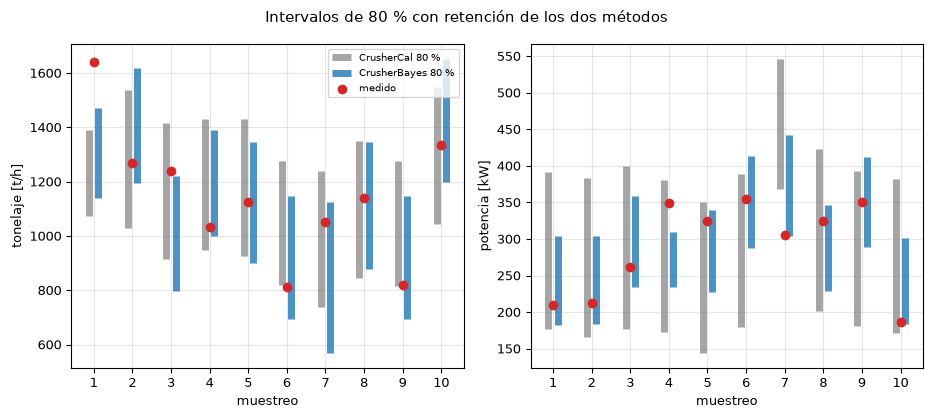

In [6]:

# Las diez predicciones con retención con el intervalo de CrusherBayes, la banda de CrusherCal y el
# valor medido
x = np.arange(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.2))
for ax, name, ylabel in zip(axes, cb.TARGETS, ('tonelaje [t/h]', 'potencia [kW]')):
    block = committed["loo"][name]
    lo, hi = np.array(block["lo80"]), np.array(block["hi80"])
    cc_lo, cc_hi = cc_band[name]
    ax.vlines(x - 0.12, cc_lo, cc_hi, color="tab:grey", lw=5, alpha=0.7, label='CrusherCal 80 %')
    ax.vlines(x + 0.12, lo, hi, color="tab:blue", lw=5, alpha=0.8, label='CrusherBayes 80 %')
    ax.scatter(x, block["measured"], color="tab:red", zorder=3, label='medido')
    ax.set_xticks(x)
    ax.set_xlabel('muestreo')
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7)
fig.suptitle('Intervalos de 80 % con retención de los dos métodos')
fig.tight_layout()
plt.show()


Los intervalos de CrusherBayes son más angostos que los de CrusherCal en ambos objetivos: un ancho medio de 439 t/h frente a 474 en el tonelaje (93 por ciento de la banda) y 118 kW frente a 210 en la potencia (56 por ciento). La cobertura de CrusherBayes es 0,8 en el tonelaje y 0,9 en la potencia (8 y 9 muestreos de 10 dentro): los muestreos 1 y 3 quedan fuera de su intervalo en el tonelaje y el muestreo 4 en la potencia, mientras la banda anidada de CrusherCal cubre 0,8 y 0,9. Con diez muestreos uno mueve la cobertura en 0,1, así que estas coberturas no se distinguen del 0,8 nominal y la figura no dice más de la calibración que el que es plausible. El estrechamiento en la potencia es una ganancia solo frente a la banda del modelo base. No hace que el intervalo de CrusherBayes sea apreciablemente más estrecho que el de un modelo más simple: las celdas de abajo dan a la recta de la abertura y a la regresión libre una banda propia, una banda anidada de sus residuos con retención, que es una construcción distinta de los cuantiles a posteriori de CrusherBayes.

La misma regla de banda de residuos que fija la banda de CrusherCal se puede aplicar a los propios residuos con retención de CrusherBayes, para preguntar si el intervalo a posteriori es mejor que una banda construida con los errores de sus predicciones puntuales: la celda fija la banda de cada muestreo con los otros nueve residuos, como hace el notebook 04 del tema 06.

In [7]:

# La regla de banda anidada de CrusherCal aplicada a los residuos con retención de CrusherBayes, para
# ambos objetivos
nested_cb = {}
for name in cb.TARGETS:
    block = committed["loo"][name]
    resid = np.array(block["measured"]) - np.array(block["pred_mean"])
    nested = loo.nested_band_coverage(resid)
    width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
    nested_cb[name] = (nested["coverage"], width)
    print(f"{name:5s} residuos de CrusherBayes, banda anidada: cobertura {nested['coverage']:.2f}, "
          f"ancho medio {width:7.1f}")


tph   residuos de CrusherBayes, banda anidada: cobertura 0.80, ancho medio   451.5
kW    residuos de CrusherBayes, banda anidada: cobertura 0.80, ancho medio   119.3


Para una comparación justa de anchos, la celda siguiente da a la recta de la abertura y a la regresión libre la misma banda anidada.

In [8]:

# La misma banda anidada para la recta de la abertura y para la regresión libre, para comparar los anchos de los tres
for name in cb.TARGETS:
    strict = crushercal["loo"][name]["strict"]
    measured = np.array(crushercal["loo"][name]["measured"])
    for model, method in {"B_lin": "recta de la abertura", "M2": "libre"}.items():
        nested = loo.nested_band_coverage(measured - np.array(strict["pred"][model]))
        width = np.mean(2 * loo.band_factor(0.8) * np.array(nested["sigma"]))
        print(f"{name:5s} {method:20s} banda anidada: cobertura {nested['coverage']:.2f}, ancho medio {width:7.1f}")


tph   recta de la abertura banda anidada: cobertura 0.80, ancho medio   478.8
tph   libre                banda anidada: cobertura 0.80, ancho medio   468.5
kW    recta de la abertura banda anidada: cobertura 0.80, ancho medio   119.6
kW    libre                banda anidada: cobertura 0.80, ancho medio   129.8


Por último, la forma dentro de la muestra de la regla, con sigma de los diez residuos, frente al intervalo a posteriori de CrusherBayes.

In [9]:

# La banda dentro de la muestra de los residuos de CrusherBayes, sigma de los diez, frente a su propio
# intervalo a posteriori
for name in cb.TARGETS:
    block = committed["loo"][name]
    band = loo.predictive_band(np.array(block["measured"]) - np.array(block["pred_mean"]))
    posterior_width = np.mean(np.array(block["hi80"]) - np.array(block["lo80"]))
    print(f"{name:5s} regla de CrusherCal dentro de la muestra sobre los residuos de CrusherBayes: "
          f"ancho {2 * band['halfwidth']:7.1f}; intervalo a posteriori: ancho {posterior_width:7.1f}")


tph   regla de CrusherCal dentro de la muestra sobre los residuos de CrusherBayes: ancho   452.4; intervalo a posteriori: ancho   439.1
kW    regla de CrusherCal dentro de la muestra sobre los residuos de CrusherBayes: ancho   119.6; intervalo a posteriori: ancho   117.7


Con la misma regla, los residuos de CrusherBayes dan una banda anidada de 119 kW en la potencia (cobertura 0,8) y 451 t/h en el tonelaje (cobertura 0,8), frente a 120 kW y 479 t/h de la recta de la abertura y 130 kW y 469 t/h de la regresión libre. En la potencia los tres modelos angostos van de 119 a 130 kW y están todos muy bajo los 210 kW del modelo base: el estrechamiento es la ganancia de tener cualquier modelo que siga a la abertura, y CrusherBayes no lo estrecha más que una recta. Puestos lado a lado en la potencia, la banda anidada de la recta de la abertura tiene 119,6 kW de ancho con cobertura 0,8 y el intervalo a posteriori de CrusherBayes 117,7 kW con cobertura 0,9: con casi el mismo ancho el intervalo a posteriori cubre un muestreo más de diez, una diferencia que diez muestreos no distinguen del azar. La forma dentro de la muestra da 120 kW frente a los 118 kW del intervalo a posteriori, así que el intervalo a posteriori es casi tan ancho como lo sería una banda de residuos de sus propios errores.

### La comparación pareada frente al método recomendado: lo que lee la vista de comparación de la App

Los puntajes de arriba ponen errores medios lado a lado. La vista de comparación del producto hace una pregunta más fina por objetivo: qué método recomendaría, y cuánto respaldan esa elección diez muestreos. El pipeline la responde en un documento propio, `data/derived/hp500/comparison.json` (contrato `hp500-comparison`), que `pipeline.hp500.comparison.build` escribe desde el documento con retención de CrusherCal `hp500/loo.json` y el documento de CrusherBayes, sin ajustar nada. El método recomendado $R$ de un objetivo es el de menor MAPE con retención entre los métodos que no son controles; la media constante y la permutación de etiquetas son controles y nunca se recomiendan. Cada otro método $M$ con predicciones por muestreo se parea con él, muestreo a muestreo:

$$d_i = \mathrm{APE}_i(M) - \mathrm{APE}_i(R), \qquad \mathrm{APE}_i(M) = 100\,\frac{\lvert \hat y^{M}_i - y_i \rvert}{y_i}, \qquad \bar d = \frac{1}{n}\sum_{i=1}^{n} d_i,$$

en puntos porcentuales, positiva cuando $M$ es peor que $R$ en el muestreo $i$. Parear quita la parte del error que ambos métodos comparten en un muestreo (un muestreo difícil para todo modelo), que una diferencia de dos MAPE deja dentro. La incertidumbre de $\bar d$ viene del bootstrap de percentiles sobre los muestreos: $B = 20.000$ remuestreos $I_b$ de los $n = 10$ índices de muestreo, sacados con reemplazo por `default_rng(42)` de numpy, y la media de $d$ en cada uno,

$$\bar d^{*}_b = \frac{1}{n}\sum_{i=1}^{n} d_{I_{b,i}}, \qquad \mathrm{IC}_{95} = \bigl[\,q_{0.025}(\bar d^{*}),\; q_{0.975}(\bar d^{*})\,\bigr], \qquad p_{\mathrm{better}} = \frac{1}{B}\sum_{b=1}^{B} \mathbf{1}\bigl[\bar d^{*}_b > 0\bigr].$$

Las victorias son los muestreos con $d_i > 0$, los que gana el método recomendado, y $p_{\mathrm{better}}$ es la fracción de remuestreos en que es mejor en promedio. El error porcentual absoluto es la medida sin escala cuya definición y asimetría exponen Hyndman y Koehler (2006), y el sorteo es el mismo con que el manuscrito de CrusherBayes imprime su intervalo pareado; los cuantiles de 2,5 y 97,5 por ciento de las medias remuestreadas lo hacen un intervalo de percentiles. La celda de Datos leyó el documento de comparación y su entrada, el documento con retención de CrusherCal; la celda imprime por objetivo el método recomendado, el segundo y cada fila pareada.

In [10]:
# La comparación pareada del pipeline y su entrada de CrusherCal: por objetivo el recomendado, el segundo y las filas
boot = paired_doc["bootstrap"]
print(f"muestreos {paired_doc['n']} | remuestreos {boot['resamples']} | semilla {boot['seed']} | "
      f"CrusherBayes incluido: {paired_doc['crusherbayes']['included']}")
for name in comparison.TARGETS:
    block = paired_doc["targets"][name]
    print(f"{name}: recomendado {block['recommended']}, segundo {block['runner_up']}")
    for row in block["paired"]:
        lo, hi = row["ci95"]
        width = hi - lo
        print(f"   {row['method']:15s} d media {row['mean_diff_pts']:+6.2f} puntos, 95 % [{lo:+6.2f}, {hi:+6.2f}], "
              f"victorias {row['wins']:2d} de {paired_doc['n']}, p_better {row['p_better']:.3f}, ancho {width:5.2f}")

muestreos 10 | remuestreos 20000 | semilla 42 | CrusherBayes incluido: True
tph: recomendado crusherbayes, segundo M0_backbone
   M0_backbone     d media  +0.09 puntos, 95 % [ -6.06,  +6.30], victorias  5 de 10, p_better 0.503, ancho 12.35
   M1_residual     d media  +1.45 puntos, 95 % [ +0.76,  +2.06], victorias  9 de 10, p_better 1.000, ancho  1.30
   M2_freeform     d media  +0.18 puntos, 95 % [ -1.01,  +1.36], victorias  6 de 10, p_better 0.623, ancho  2.37
   B_lin           d media  +1.67 puntos, 95 % [ -2.23,  +4.61], victorias  8 de 10, p_better 0.825, ancho  6.84
   constant_mean   d media  +6.29 puntos, 95 % [ -2.19, +15.85], victorias  5 de 10, p_better 0.913, ancho 18.04
kW: recomendado B_lin, segundo M2_freeform
   M0_backbone     d media +13.17 puntos, 95 % [ +7.09, +18.93], victorias  8 de 10, p_better 1.000, ancho 11.83
   M1_residual     d media +12.59 puntos, 95 % [ +5.76, +21.60], victorias 10 de 10, p_better 1.000, ancho 15.85
   M2_freeform     d media  +1.26 punto

En el tonelaje el método recomendado es CrusherBayes, con 12,00 por ciento, y el segundo es el modelo base: su diferencia pareada media es +0,09 puntos con un intervalo de 95 por ciento de -6,06 a +6,30, CrusherBayes gana 5 de los 10 muestreos y es mejor en promedio en el 50,3 por ciento de los remuestreos, una moneda al aire. Un solo método queda separado de él, el modelo de residuo acotado, +1,45 puntos con un intervalo de +0,76 a +2,06 y peor en 9 muestreos de 10; la regresión libre, la recta de la abertura y la media constante tienen intervalos que contienen el cero. En la potencia el método recomendado es la recta de la abertura, con 12,78 por ciento, y la regresión libre es la segunda con +1,26 puntos (-1,91 a +5,27). CrusherBayes queda 1,54 puntos detrás de la recta con un intervalo de -1,11 a +4,10; la recta gana 5 muestreos y CrusherBayes los otros 5, y la recta es mejor en promedio en el 87,0 por ciento de los remuestreos. El modelo base, el modelo de residuo acotado, el modelo de Morrell por el origen y la media constante quedan separados de la recta, con todo su intervalo sobre cero. La columna de ancho dice cuánto dejan abierto diez muestreos: 1,30 puntos para el modelo de residuo acotado en el tonelaje frente a 12,35 del modelo base, y 5,21 puntos para CrusherBayes en la potencia. Una recomendación es entonces un orden de medias, y el intervalo dice cuánto lo respaldan diez muestreos: en ambos objetivos el intervalo del segundo contiene el cero.

**De dónde sale el intervalo.** La celda siguiente recalcula la fila de CrusherBayes en la potencia desde las propias predicciones con retención, sin el módulo de comparación: las medias predictivas a posteriori del documento de CrusherBayes y las predicciones con retención de la recta de la abertura del documento de CrusherCal, sus errores porcentuales absolutos, las diez diferencias, los 20.000 remuestreos con la semilla del pipeline y los dos cuantiles. Imprime la fila del documento junto a la recalculada; la única comprobación de reproducción del notebook, en la sección Evidencia, ata las dos.

In [11]:
# La fila de CrusherBayes en la potencia, recalculada desde las predicciones con retención
y_kw = np.array(loo_doc["loo"]["kW"]["measured"])
ape_cb = 100 * np.abs(np.array(committed["loo"]["kW"]["pred_mean"]) - y_kw) / y_kw
ape_line = 100 * np.abs(np.array(loo_doc["loo"]["kW"]["strict"]["pred"]["B_lin"]) - y_kw) / y_kw
d = ape_cb - ape_line
draws = np.random.default_rng(comparison.BOOT_SEED).integers(0, d.size, size=(comparison.BOOT_RESAMPLES, d.size))
resampled = d[draws].mean(axis=1)
ci_lo, ci_hi = np.quantile(resampled, [0.025, 0.975])
print("d_i [puntos]:", " ".join(f"{v:+.2f}" for v in d))
print(f"recalculado: d media {d.mean():+.4f}, 95 % [{ci_lo:+.4f}, {ci_hi:+.4f}], victorias {int(np.sum(d > 0))}, "
      f"p_better {np.mean(resampled > 0):.4f}")
row_cb = next(r for r in paired_doc["targets"]["kW"]["paired"] if r["method"] == "crusherbayes")
doc_lo, doc_hi = row_cb["ci95"]
print(f"documento:   d media {row_cb['mean_diff_pts']:+.4f}, 95 % [{doc_lo:+.4f}, {doc_hi:+.4f}], "
      f"victorias {row_cb['wins']}, p_better {row_cb['p_better']:.4f}")
spread = d.std(ddof=1) / np.sqrt(d.size)
print(f"de bootstrap de la media {resampled.std():.3f}, s/sqrt(n) {spread:.3f}, razón {resampled.std() / spread:.3f}, "
      f"sqrt((n-1)/n) {np.sqrt((d.size - 1) / d.size):.3f}")

d_i [puntos]: +4.17 +4.73 +6.15 -0.25 -3.10 -1.94 -5.87 +7.24 -0.83 +5.07
recalculado: d media +1.5368, 95 % [-1.1117, +4.0956], victorias 5, p_better 0.8700
documento:   d media +1.5369, 95 % [-1.1117, +4.0956], victorias 5, p_better 0.8700
de bootstrap de la media 1.341, s/sqrt(n) 1.417, razón 0.947, sqrt((n-1)/n) 0.949


La figura dibuja las diez diferencias pareadas de la potencia, muestreo a muestreo, y la distribución de las 20.000 medias remuestreadas con su intervalo de 95 por ciento.

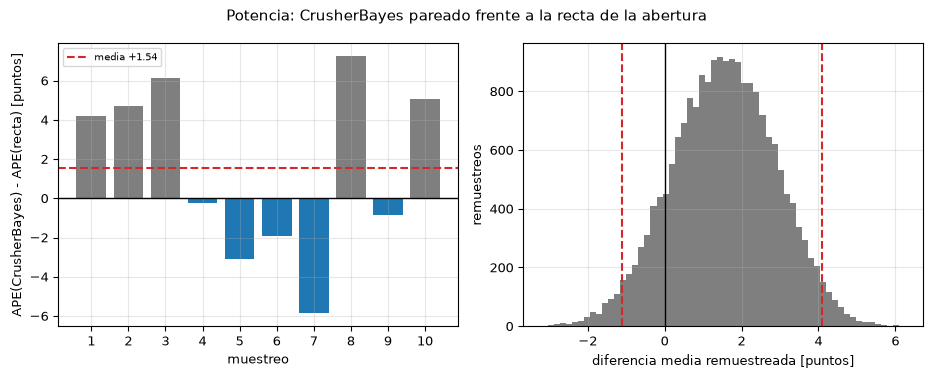

In [12]:
# Las diez diferencias pareadas y la distribución de las 20.000 medias remuestreadas, con el intervalo de 95 %
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))
surveys_axis = np.arange(1, d.size + 1)
axes[0].bar(surveys_axis, d, color=np.where(d > 0, "tab:grey", "tab:blue"))
axes[0].axhline(0, color="black", lw=1)
axes[0].axhline(d.mean(), color="tab:red", ls="--", lw=1.5, label=f"media {d.mean():+.2f}")
axes[0].set_xticks(surveys_axis)
axes[0].set_xlabel("muestreo")
axes[0].set_ylabel("APE(CrusherBayes) - APE(recta) [puntos]")
axes[0].legend(fontsize=7)
axes[1].hist(resampled, bins=60, color="tab:grey")
for edge in (ci_lo, ci_hi):
    axes[1].axvline(edge, color="tab:red", ls="--", lw=1.5)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_xlabel("diferencia media remuestreada [puntos]")
axes[1].set_ylabel("remuestreos")
fig.suptitle("Potencia: CrusherBayes pareado frente a la recta de la abertura")
fig.tight_layout()
plt.show()

El panel izquierdo muestra por qué la media sola engaña. La recta es mejor en los muestreos 1, 2, 3, 8 y 10, por 4,17 a 7,24 puntos, y CrusherBayes en los muestreos 4, 5, 6, 7 y 9 (azul), por 0,25 a 5,87 puntos: cinco victorias cada uno, y la media de +1,54 puntos es el balance de dos grupos de diferencias grandes de signo opuesto, no una brecha chica repetida en cada muestreo. El panel derecho es la distribución de las medias remuestreadas. Sus cuantiles de 2,5 y 97,5 por ciento, -1,11 y +4,10 puntos, son el intervalo del documento hasta el cuarto decimal impreso (la media difiere ahí solo porque el documento la guarda con seis decimales, 1,53685, que redondea hacia arriba), y el 87,0 por ciento de su masa queda sobre cero, el p_better del documento. El intervalo contiene el cero, así que diez muestreos no establecen que la recta sea el mejor predictor de potencia, y menos aún que lo sea CrusherBayes. Lo que la figura no muestra es la influencia de cada muestreo en el orden mismo, que miden las celdas siguientes.

**Límites con diez muestreos.** Dos debilidades del intervalo de percentiles aparecen con este tamaño. La primera es su ancho: la distribución bootstrap de una media sobre $n$ valores tiene la varianza del estimador de sustitución,

$$\operatorname{Var}^{*}\bigl(\bar d^{*}\bigr) = \frac{1}{n}\cdot\frac{1}{n}\sum_{i=1}^{n}\bigl(d_i - \bar d\bigr)^2 = \frac{n-1}{n}\cdot\frac{s^2}{n},$$

no $s^2/n$: cada remuestreo saca de las diez diferencias observadas tal como están, así que su dispersión es su varianza de sustitución, que divide por $n$ donde la varianza muestral $s^2$ divide por $n-1$. La celda de arriba imprime una desviación estándar bootstrap de 1,341 puntos frente a $s/\sqrt{n} = 1{,}417$, una razón de 0,947 donde $\sqrt{(n-1)/n} = 0{,}949$: con diez muestreos el intervalo es cerca de 5 por ciento más angosto que un intervalo normal con la varianza muestral, y puede cubrir menos de 95 por ciento. Describe la dispersión de los remuestreos; no es un 95 por ciento garantizado. La segunda debilidad es el orden: el método recomendado es el mínimo de unas pocas medias de diez números, y un muestreo puede moverlo. La celda siguiente quita cada muestreo por turno, recalcula el MAPE de cada método que no es control desde los errores por muestreo del documento, e imprime el método que recomendaría cada conjunto de nueve muestreos.

In [13]:
# Un muestreo fuera del orden: el método que recomienda cada conjunto de nueve, desde los errores del documento
n_surveys = paired_doc["n"]
for name in comparison.TARGETS:
    block = paired_doc["targets"][name]
    scored = {m["id"]: np.array(m["ape_pct"]) for m in block["methods"] if not m["control"] and m["ape_pct"]}
    picks = []
    for drop in range(n_surveys):
        keep = np.delete(np.arange(n_surveys), drop)
        picks.append(min(scored, key=lambda rid: scored[rid][keep].mean()))
    counts = {rid: picks.count(rid) for rid in dict.fromkeys(picks)}
    print(f"{name}: con los diez {block['recommended']}; sin el muestreo 1 a 10: {', '.join(picks)}")
    print(f"     conjuntos de nueve por método recomendado: {counts}")

tph: con los diez crusherbayes; sin el muestreo 1 a 10: M0_backbone, M2_freeform, M2_freeform, crusherbayes, M0_backbone, M0_backbone, crusherbayes, M0_backbone, M0_backbone, M2_freeform
     conjuntos de nueve por método recomendado: {'M0_backbone': 5, 'M2_freeform': 3, 'crusherbayes': 2}
kW: con los diez B_lin; sin el muestreo 1 a 10: Morrell_noload, B_lin, M2_freeform, B_lin, B_lin, B_lin, B_lin, B_lin, B_lin, B_lin
     conjuntos de nueve por método recomendado: {'Morrell_noload': 1, 'B_lin': 8, 'M2_freeform': 1}


En la potencia la recta sigue recomendada en 8 de los 10 conjuntos de nueve muestreos: sin el muestreo 1 la reemplaza el modelo de Morrell con término en vacío, y sin el muestreo 3 la regresión libre. En el tonelaje el orden no sobrevive. CrusherBayes, recomendado con los diez muestreos, solo es recomendado en 2 de los 10 conjuntos de nueve (sin el muestreo 4 o sin el 7), el modelo base en 5 y la regresión libre en 3. Eso es lo que significa en la práctica un intervalo de -6,06 a +6,30 puntos alrededor de una diferencia media de +0,09: la recomendación de tonelaje la decide qué muestreos están en el conjunto, y por eso la vista de comparación imprime el intervalo junto al método recomendado. Un intervalo que contiene el cero dice que el orden no está resuelto; no dice que los métodos sean iguales, y más muestreos podrían adelantar a cualquiera.

**Úsalo con tus propios datos, y cuando falta el documento.** `comparison.build(loo, cb, version)` recibe los dos documentos como diccionarios, así que un lector que agregue muestreos a `data/examples/hp500-surveys.csv` y vuelva a generar (`python data-pipeline/run.py hp500`, luego `python data-pipeline/run.py comparison`) obtiene las filas pareadas de sus propios muestreos, y `comparison.paired(ape_method, ape_best, idx)` parea dos vectores cualesquiera de errores por muestreo sobre cualquier índice de remuestreo. Dos estados cambian lo que la vista puede mostrar. Sin el documento de CrusherBayes la comparación igual se construye, con los métodos de CrusherCal solos, y lo dice en su nota. Sin el documento de comparación, las reglas de disponibilidad marcan el contrato como ausente y dan la razón que la App muestra en lugar del recuadro de diferencia pareada y de la frase de certeza de la historia, nunca un número de una generación anterior. La celda construye el primer estado desde el documento de CrusherCal y calcula el segundo sobre una carpeta derivada que no existe, sin escribir nada.

In [14]:
# CrusherBayes fuera: la comparación solo con CrusherCal; luego la disponibilidad sin el documento de comparación
without_cb = comparison.build(loo_doc, None, version)
print("nota:", without_cb["crusherbayes"]["note"]["es"])
for name in comparison.TARGETS:
    print(f"{name}: recomendado sin CrusherBayes {without_cb['targets'][name]['recommended']}")
not_baked = ROOT / "data/derived/not-baked"
state = readiness.compute(repo_root=ROOT, derived_root=not_baked, models_dir=not_baked / "models")
row_absent = next(r for r in state["contracts"] if r["id"] == "hp500-comparison")
print(f"hp500-comparison sin su documento: {row_absent['state']}, razón: {row_absent['reason']['es']}")

nota: CrusherBayes no está en esta comparación: su documento (hp500/crusherbayes.json) no está en esta versión, así que solo se comparan los métodos de CrusherCal.
tph: recomendado sin CrusherBayes M0_backbone
kW: recomendado sin CrusherBayes B_lin
hp500-comparison sin su documento: missing, razón: La validación HP500 no se generó en esta versión.


Sin CrusherBayes la recomendación de tonelaje pasa al modelo base, el segundo de arriba, y la de potencia se queda con la recta, a la que CrusherBayes no superó; la nota es la frase que la vista de comparación imprime en ese caso. Sin el documento el contrato queda ausente (missing), con la razón de que la validación HP500 no se generó en esta versión, la misma que lleva todo documento HP500 cuando falta: el lector sabe por qué no hay intervalo pareado, y el resto de la vista de comparación sigue funcionando con el documento con retención de CrusherCal. Antes de confiar en una recomendación de una generación propia, revise tres campos de su documento de comparación: `crusherbayes.included`, si se parearon los métodos que espera; `engine_version` frente al VERSION del producto, porque la disponibilidad llama desactualizado (stale) a un documento anterior; y el `ci95` del segundo, si contiene el cero.

## Evidencia

**Qué identifican los muestreos.** Un a posteriori puede ser tan ancho como su a priori para un parámetro que los datos no restringen. La contracción, la desviación estándar a posteriori sobre la del a priori, lo mide para el ajuste con los diez muestreos: bajo cerca de 0,5 los muestreos identifican el parámetro, cerca de 1 lo dejan donde empezó. La celda lista cada parámetro, ordenado, del documento versionado.

In [15]:

# La tabla de contracción del ajuste con los diez muestreos, ordenada, con la línea de identificación
# en 0.5
table = sorted(committed["contraction"], key=lambda row: row["contraction"])
for row in table:
    print(f"{row['name']:26s} nominal {row['nominal']:8.2f}  posterior {row['posterior_mean']:9.2f} ", end="")
    print(f"sd {row['posterior_sd']:8.3f}  contraction {row['contraction']:.2f}")


sigma_tph                  nominal    60.00  posterior    145.23 sd   39.037  contraction 0.30
sigma_kW                   nominal    15.00  posterior     38.81 sd   10.754  contraction 0.33
discrepancy_tph_f80        nominal     0.00  posterior     56.57 sd   47.627  contraction 0.34
discrepancy_tph_css        nominal     0.00  posterior    100.84 sd   48.996  contraction 0.35
discrepancy_kW_f80         nominal     0.00  posterior     -5.16 sd   13.026  contraction 0.36
discrepancy_kW_css         nominal     0.00  posterior    -57.07 sd   13.704  contraction 0.38
q_ref_tph                  nominal   647.00  posterior    646.35 sd   75.745  contraction 0.45
zeta                       nominal     1.30  posterior      1.14 sd    0.223  contraction 0.73
pn_kw                      nominal   110.00  posterior     86.35 sd   38.039  contraction 0.80
wi_kwh_t                   nominal     9.00  posterior      8.39 sd    1.294  contraction 0.85
discrepancy_tph_constant   nominal     0.00  poste

La figura dibuja la misma tabla como barras, con la línea de identificación en 0,5 y el a priori en 1.

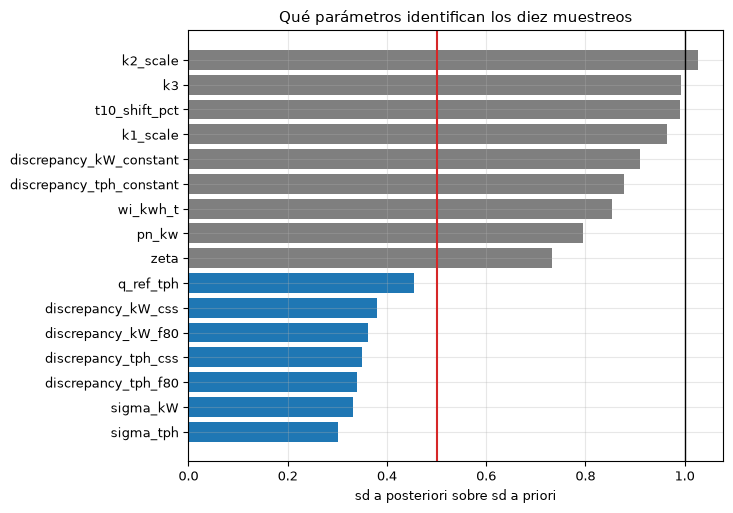

In [16]:

# Desviación estándar a posteriori sobre a priori de cada parámetro, del documento
fig, ax = plt.subplots(figsize=(7.4, 5.2))
names = [row["name"] for row in table]
values = [row["contraction"] for row in table]
ax.barh(names, values, color=["tab:blue" if v < 0.5 else "tab:grey" for v in values])
ax.axvline(0.5, color="tab:red", lw=1.5)
ax.axvline(1.0, color="black", lw=1)
ax.set_xlabel('sd a posteriori sobre sd a priori')
ax.set_title('Qué parámetros identifican los diez muestreos')
fig.tight_layout()
plt.show()


7 de los 16 parámetros quedan bajo 0,5: q_ref_tph, sigma_tph, sigma_kW, discrepancy_tph_css, discrepancy_tph_f80, discrepancy_kW_css, discrepancy_kW_f80. Son la base de capacidad (el único escalar que mueve el tonelaje, notebook 01), las dos escalas de ruido y las pendientes de discrepancia en la abertura y en el f80 de alimentación. Todo lo demás queda sobre 0,7, cerca de su a priori o apenas estrechado: `zeta` en 0,73, `wi_kwh_t` en 0,85, `pn_kw` en 0,80, y `k1_scale`, `k2_scale`, `k3` y `t10_shift_pct` en 0,96, 1,03, 0,99 y 0,99, las constantes de la discrepancia en 0,91 y 0,88. Los diez muestreos no determinan entonces las constantes de Andersen K1, K2 y K3 ni el desplazamiento de t10 de los modelos de clasificación y fractura: el a posteriori de esos escalares es su a priori, y una predicción que depende de ellos la lleva la discrepancia. Es un resultado sobre los datos, no un defecto del muestreador. La figura no muestra si más muestreos los identificarían; muestra que estos diez, que varían solo la abertura y el tamaño de alimentación, no lo hacen.

**El criterio de descarte.** La regla se aplica con la función del propio módulo, a partir de los puntajes y anchos de intervalo calculados en este notebook, término por término.

In [17]:

# El criterio de descarte del SDD, evaluado con la función del módulo sobre los números calculados
# arriba, redondeados como los redondea el cálculo (MAPE y anchos a dos decimales, cobertura a tres)
verdict = cb.kill_criterion(
    power_mape=round(cb_score["kW"]["mape"], 2), power_mape_blin=round(comparator_mape["kW"]["B_lin"], 2),
    tph_mape=round(cb_score["tph"]["mape"], 2), tph_mape_m0=round(comparator_mape["tph"]["M0"], 2),
    coverage={t: round(cb_score[t]["coverage"], 3) for t in cb.TARGETS},
    width={t: round(cb_score[t]["width"], 2) for t in cb.TARGETS},
    width_crushercal={t: round(float(np.mean(cc_band[t][1] - cc_band[t][0])), 2) for t in cb.TARGETS})
v = verdict
print(f"(a) MAPE de potencia {v['power_mape_pct']:.2f} % "
      f"frente a la recta de la abertura {v['power_mape_blin_pct']:.2f} %: "
      f"ganancia {v['power_gain_over_blin_pts']:+.2f} puntos, se necesitan 3.0, "
      f"supera por el margen: {v['a_power_beats_blin_by_margin']}")
print(f"(a) MAPE de tonelaje {v['tph_mape_pct']:.2f} % frente al modelo base {v['tph_mape_m0_pct']:.2f} %: "
      f"ganancia {v['tph_gain_over_m0_pts']:+.2f} puntos, supera por el margen: {v['a_tph_beats_m0_by_margin']}")
print(f"(a) se cumple, es decir ninguno supera a su comparador por el margen: {v['a_holds']}")
print(f"(b) cobertura {v['coverage']}, fuera de 0.7 a 0.9: {v['coverage_outside_band']}")
print(f"(b) banda más ancha que la de CrusherCal: {v['band_wider_than_crushercal']}, "
      f"así que (b) se cumple: {v['b_holds']}")
print(f"veredicto: {v['verdict']}")


(a) MAPE de potencia 14.31 % frente a la recta de la abertura 12.78 %: ganancia -1.53 puntos, se necesitan 3.0, supera por el margen: False
(a) MAPE de tonelaje 12.00 % frente al modelo base 12.09 %: ganancia +0.09 puntos, supera por el margen: False
(a) se cumple, es decir ninguno supera a su comparador por el margen: True
(b) cobertura {'tph': 0.8, 'kW': 0.9}, fuera de 0.7 a 0.9: {'tph': False, 'kW': False}
(b) banda más ancha que la de CrusherCal: {'tph': False, 'kW': False}, así que (b) se cumple: False
veredicto: kept


La parte (a) de la regla se cumple: la ganancia de potencia sobre la recta de la abertura es -1,53 puntos, negativa, donde se habrían necesitado 9,78 por ciento (el 12,78 de la recta de la abertura menos el margen), y la ganancia de tonelaje sobre el modelo base es +0,09 puntos frente a los 3 exigidos. La parte (b) no se cumple: ambas coberturas quedan dentro de 0,7 a 0,9 y ambas bandas son más angostas que la de CrusherCal. La regla descarta el método solo cuando (a) y (b) se cumplen a la vez, así que el veredicto es **conservado** (kept en el documento): CrusherBayes permanece en el producto como predictor porque su intervalo es más estrecho que la banda de CrusherCal con una cobertura dentro de 0,7 a 0,9, aunque no supera a la recta de la abertura en la potencia y su intervalo es casi tan ancho como la banda de la recta de la abertura (117,7 frente a 119,6 kW). El veredicto descansa solo en la parte (b), y en su borde: la cobertura de potencia de 0,9 está en el límite superior inclusivo de 0,7 a 0,9, así que un muestreo más de diez dentro del intervalo de potencia daría 1,0, fuera de la banda, (b) se cumpliría y el método se descartaría. El criterio dice además que aun así la tabla de identificabilidad es el resultado, y esa es la sección de arriba. Sigue la única comprobación de reproducción del notebook: los puntajes, la ganancia de potencia y el veredicto recalculados aquí frente al documento versionado, y el intervalo pareado de potencia de CrusherBayes frente a la recta de la abertura, recalculado en la sección Comparación, frente al documento de comparación.

In [18]:

# La única comprobación de reproducción: los puntajes, la ganancia de potencia y el veredicto recalculados
# aquí frente al documento versionado, y el intervalo pareado de potencia frente al documento de comparación
doc_kc = committed["kill_criterion"]
scores_equal = all(abs(cb_score[t]["mape"] - committed["loo"][t]["scores"]["mape_pct"]) < 0.01 for t in cb.TARGETS)
gain_equal = verdict["power_gain_over_blin_pts"] == doc_kc["power_gain_over_blin_pts"]
paired_equal = [round(float(v), 6) for v in (d.mean(), ci_lo, ci_hi)] == [row_cb["mean_diff_pts"], *row_cb["ci95"]]
print(f"los puntajes igualan al documento: {scores_equal} | la ganancia de potencia iguala a la del documento "
      f"({doc_kc['power_gain_over_blin_pts']:+.2f}): {gain_equal} | el veredicto iguala al del documento "
      f"({doc_kc['verdict']}): {verdict['verdict'] == doc_kc['verdict']} | el intervalo pareado de potencia "
      f"iguala al del documento de comparación: {paired_equal}")


los puntajes igualan al documento: True | la ganancia de potencia iguala a la del documento (-1.53): True | el veredicto iguala al del documento (kept): True | el intervalo pareado de potencia iguala al del documento de comparación: True


**Qué muestra el registro de convergencia.** Las cadenas versionadas son las más largas que corre el cálculo, y el documento registra para cada a posteriori si el muestreador pasó su propio diagnóstico, una cadena de al menos 50 tiempos de autocorrelación. La celda imprime ese registro.

In [19]:

# El registro de convergencia de las cadenas versionadas
print('a posteriori   tau [pasos]   cadena sobre tau   convergió')
for row in record:
    print(f"{row['fold']!s:9s} {row['tau_max']:12.1f} {row['chain_over_tau']:16.1f} {row['converged']!s:>11}")


a posteriori   tau [pasos]   cadena sobre tau   convergió
1                 52.6            114.1        True
2                 52.7            113.8        True
3                 54.7            109.7        True
4                 84.8             70.7        True
5                 52.7            113.9        True
6                 48.0            125.0        True
7                 55.1            108.9        True
8                 48.9            122.7        True
9                 52.6            114.1        True
10                50.7            118.3        True
all               48.6            123.5        True


Las 11 distribuciones a posteriori lo pasan: las cadenas de 7000 pasos tienen tiempos de autocorrelación de 48 a 85 pasos y largos de 70,7 a 125,0 veces eso, sobre las 50 que exige el pipeline, con los movimientos de evolución diferencial de ter Braak (2006) y de ter Braak y Vrugt (2008) que usa el muestreador (un cálculo anterior con el movimiento de estiramiento de Goodman y Weare (2010) no lo alcanzó). Los puntajes de arriba son entonces estimaciones de cadenas que pasaron el diagnóstico del propio muestreador. Es una afirmación sobre las cadenas y no una prueba de convergencia: el diagnóstico es un criterio, y diez muestreos dejan anchos a los parámetros débilmente identificados cualquiera sea el largo de la cadena, así que las razones de contracción cercanas a 1 significan que los datos no los restringen, no que el muestreador falló.

### Sensibilidad de la comparación a los diez muestreos: la incertidumbre de las dos ganancias

El veredicto descansa en dos diferencias de errores medidas en diez muestreos, $\Delta_P = -1{,}53$ y $\Delta_Q = +0{,}09$ puntos, y una diferencia medida en diez puntos tiene su propia incertidumbre, que los valores puntuales esconden. La celda la estima con un bootstrap sobre los muestreos: remuestrea los diez muestreos con reemplazo 4000 veces, con una semilla fija, recalcula las dos ganancias en cada remuestreo desde las predicciones retenidas ya disponibles (sin reajustar, así que es la incertidumbre de la comparación dadas las predicciones, no la de los ajustes), e informa los intervalos de 80 y 95 por ciento y la fracción de remuestreos en que cada ganancia alcanza el margen de 3 puntos.

kW   ganancia sobre la recta de la abertura: 80 % [-3.26, +0.19] | 95 % [-4.13, +1.07] puntos | fracción en o sobre 3 puntos: 0.000
tph  ganancia sobre el modelo base: 80 % [-3.98, +4.40] | 95 % [-6.12, +6.52] puntos | fracción en o sobre 3 puntos: 0.183


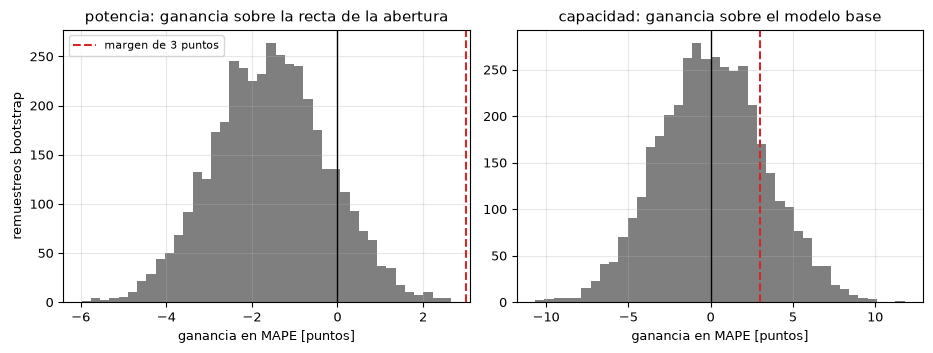

In [20]:
# Bootstrap sobre los diez muestreos de la ganancia de potencia sobre la recta de la abertura y de capacidad sobre la
# columna vertebral
rng = np.random.default_rng(2026)
y = {t: np.array(committed["loo"][t]["measured"]) for t in cb.TARGETS}
cb_pred = {t: np.array(committed["loo"][t]["pred_mean"]) for t in cb.TARGETS}
ref_pred = {"kW": np.array(crushercal["loo"]["kW"]["strict"]["pred"]["B_lin"]),
            "tph": np.array(crushercal["loo"]["tph"]["strict"]["pred"]["M0"])}
gains = {t: [] for t in cb.TARGETS}
for _ in range(4000):
    pick = rng.integers(0, 10, 10)
    for t in cb.TARGETS:
        gains[t].append(loo.mape(y[t][pick], ref_pred[t][pick]) - loo.mape(y[t][pick], cb_pred[t][pick]))
for t, against in (("kW", "la recta de la abertura"), ("tph", "el modelo base")):
    g = np.array(gains[t])
    lo80, hi80, lo95, hi95 = np.percentile(g, [10, 90, 2.5, 97.5])
    print(f"{t:4s} ganancia sobre {against}: 80 % [{lo80:+.2f}, {hi80:+.2f}] | 95 % [{lo95:+.2f}, {hi95:+.2f}] puntos",
          f"| fracción en o sobre 3 puntos: {np.mean(g >= 3):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.6))
panels = ((axes[0], "kW", "potencia: ganancia sobre la recta de la abertura"),
          (axes[1], "tph", "capacidad: ganancia sobre el modelo base"))
for ax, t, title in panels:
    ax.hist(gains[t], bins=40, color="tab:grey")
    ax.axvline(0, color="black", lw=1)
    ax.axvline(3, color="tab:red", ls="--", lw=1.5, label="margen de 3 puntos")
    ax.set_xlabel("ganancia en MAPE [puntos]")
    ax.set_title(title)
axes[0].set_ylabel("remuestreos bootstrap")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

Los dos intervalos cruzan el cero, así que con diez muestreos no queda establecido ningún signo: la ganancia de potencia sobre la recta de la abertura podría ser una pérdida de varios puntos o una ganancia pequeña, y la ganancia de capacidad sobre la columna vertebral está centrada cerca de cero con una dispersión de unos pocos puntos a cada lado. Ninguno de los remuestreos de potencia y 18,3 por ciento de los de capacidad alcanzan el margen de 3 puntos, así que la parte (a) de la regla se cumpliría en la mayoría de los remuestreos, como se cumple con los diez observados. Esta es la incertidumbre que llevan los valores puntuales de la comparación, y es más ancha que las diferencias mismas; también es una cota inferior, porque mantiene fijas las predicciones y un reajuste sobre los muestreos remuestreados agregaría la variación de los ajustes. La lectura que hace el producto es aquella para la que se escribió el margen: un método que no supera 3 puntos con diez muestreos no ha mostrado una ganancia de precisión, sea cual sea el signo de su estimación puntual, y el resultado negativo en potencia se informa como negativo, no como empate.

### Úsalo con tus propios datos: el criterio de descarte sobre los puntajes de tu propia calibración

La regla recibe números, no documentos, así que un lector que calibre una tabla propia (notebook 02) y la puntúe con retención, como hace este notebook, la aplica con una llamada. La celda muestra la llamada dos veces con puntajes escritos que no son resultados de ninguna calibración, solo entradas elegidas para mostrar los dos desenlaces: una calibración cuyo error de potencia queda 4 puntos bajo el de la recta de la abertura, que la parte (a) conserva sean como sean sus intervalos, y una sin ganancia de precisión y con una cobertura de potencia de 0,6, fuera de la ventana, que la regla descarta. También imprime los campos del bloque retenido del documento versionado, `loo`, que es donde una corrida propia de `cb.build` pondría los mismos números (contrato `hp500-crusherbayes`).

In [21]:
# El criterio sobre dos juegos de puntajes escritos (entradas para mostrar la llamada), y los campos loo del documento
cases = {"gana en potencia por 4 puntos": dict(power_mape=8.78, tph_mape=12.0, coverage={"tph": 0.8, "kW": 0.8}),
         "sin ganancia, cobertura 0,6": dict(power_mape=13.5, tph_mape=12.0, coverage={"tph": 0.8, "kW": 0.6})}
for label, scores in cases.items():
    outcome = cb.kill_criterion(power_mape_blin=12.78, tph_mape_m0=12.09, width={"tph": 430.0, "kW": 115.0},
                                width_crushercal={"tph": 473.8, "kW": 209.8}, **scores)
    print(f"{label:31s} (a) {outcome['a_holds']!s:5s} (b) {outcome['b_holds']!s:5s} -> {outcome['verdict']}")
print("campos del bloque loo versionado, potencia:", sorted(committed["loo"]["kW"]))

gana en potencia por 4 puntos   (a) False (b) False -> kept
sin ganancia, cobertura 0,6     (a) True  (b) True  -> dropped as a predictor
campos del bloque loo versionado, potencia: ['hi80', 'lo80', 'measured', 'pred_mean', 'scores']


El primer juego lo conserva la parte (a) por sí sola: una ganancia de potencia de 4 puntos sobre la recta de la abertura supera el margen, así que el método se queda hagan lo que hagan sus intervalos. El segundo se descarta: ninguna ganancia de precisión en los objetivos hace que (a) se cumpla, y una cobertura de potencia de 0,6, fuera de 0,7 a 0,9, hace que (b) también se cumpla. El método versionado queda entre ambos, conservado porque (b) no se cumple, ya que sus intervalos están calibrados dentro de la ventana y son más angostos que los de CrusherCal, mientras (a) sí se cumple. Un lector que corra la calibración en otra máquina debería fijar su propio margen y su ventana antes de mirar los puntajes, como el documento de diseño fijó estos, y debería leer el bloque retenido de su propio documento, la predicción y el intervalo de cada muestreo y los puntajes construidos con ellos, antes del veredicto, porque el veredicto comprime justamente la incertidumbre que mostró el bootstrap de arriba.

## Resultados

**Respuesta:** CrusherBayes no predice un muestreo retenido mejor que la recta de la abertura; sí da un intervalo más estrecho que la banda de CrusherCal con una cobertura dentro de 0,7 a 0,9, y el criterio lo conserva. Con retención en los diez muestreos tiene un error de potencia de 14,31 por ciento frente a 12,78 de la recta de la abertura (1,53 puntos detrás) y 25,94 del modelo base, y un error de tonelaje de 12,00 por ciento frente a 12,09 del modelo base, una ganancia de 0,09 puntos que diez muestreos no distinguen de cero. Sus intervalos de 80 por ciento tienen 118 kW y 439 t/h de ancho frente a 210 kW y 474 t/h de CrusherCal, con 9 y 8 muestreos de 10 dentro. Es una ganancia frente a la banda del modelo base, no frente a una recta: la banda anidada de la recta de la abertura en la potencia ya tiene 119,6 kW de ancho con cobertura 0,8, frente a 117,7 kW con cobertura 0,9 de CrusherBayes, un muestreo de diez de diferencia. Los muestreos identifican la base de capacidad (contracción 0,45), el ruido y las pendientes de discrepancia, y dejan K1, K2, K3 y el desplazamiento de t10 en su a priori (contracción 0,96 a 1,03). El criterio de descarte, recalculado aquí con los números del propio notebook, da el veredicto conservado que registra el documento, porque la parte (b) no se cumple, y por poco: la cobertura de potencia de 0,9 está en el borde de 0,7 a 0,9. Las cadenas pasaron su propio diagnóstico en 11 de las 11 distribuciones a posteriori, con 70,7 a 125,0 tiempos de autocorrelación. La comparación pareada del producto (contrato `hp500-comparison`) recomienda CrusherBayes en el tonelaje y la recta de la abertura en la potencia; CrusherBayes queda detrás de la recta en la potencia por +1,54 puntos con un intervalo de 95 por ciento de -1,11 a +4,10, recalculado aquí desde las predicciones con retención, y en el tonelaje su recomendación se sostiene en solo 2 de los 10 conjuntos de nueve muestreos.

## Resumen

CrusherBayes se mide aquí frente al criterio que se escribió antes de correrlo. Estrecha el intervalo predictivo del modelo base en la potencia de 210 a 118 kW y reduce el error de potencia del modelo base de 25,94 a 14,31 por ciento, pero el competidor más simple, una recta sobre la abertura, predice la potencia igual o mejor (12,78 por ciento) y ya da una banda casi igual de estrecha (119,6 kW con cobertura 0,8), y el método no afirma otra cosa. Lo que agrega y ningún ajuste puntual da es la tabla de identificabilidad: con diez muestreos de una máquina los datos dicen qué son la capacidad y el ruido y nada de las constantes de clasificación y fractura. El resultado se sostiene en cadenas que pasaron su diagnóstico de convergencia en las once distribuciones a posteriori, así que las razones de contracción se pueden citar como medidas, dentro de lo que diez muestreos pueden mostrar.

Con diez muestreos los intervalos bootstrap de las dos ganancias cruzan el cero y rara vez alcanzan el margen, y la regla que las pesa recibe los puntajes propios de un lector en una llamada. La comparación pareada dice lo mismo muestreo a muestreo: cinco victorias para CrusherBayes y cinco para la recta en la potencia, y una recomendación de tonelaje que quitar un muestreo cambia en 8 de 10 casos.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Kennedy, M. C., O'Hagan, A. (2001), Bayesian calibration of computer models, Journal of the Royal Statistical Society B 63(3), 425-464. https://doi.org/10.1111/1467-9868.00294
- ter Braak, C. J. F. (2006), A Markov chain Monte Carlo version of the genetic algorithm differential evolution: easy Bayesian computing for real parameter spaces, Statistics and Computing 16, 239-249. https://doi.org/10.1007/s11222-006-8769-1
- ter Braak, C. J. F., Vrugt, J. A. (2008), Differential evolution Markov chain with snooker updater and fewer chains, Statistics and Computing 18, 435-446. https://doi.org/10.1007/s11222-008-9104-9
- Goodman, J., Weare, J. (2010), Ensemble samplers with affine invariance, Communications in Applied Mathematics and Computational Science 5(1), 65-80. https://doi.org/10.2140/camcos.2010.5.65
- Hyndman, R. J., Koehler, A. B. (2006), Another look at measures of forecast accuracy, International Journal of Forecasting 22(4), 679-688. https://doi.org/10.1016/j.ijforecast.2006.03.001